# Differential Equations
Python has many libraries dedicated to these equations. SciPy (a cousin to NumPy) has a great tool called solve_ivp (initial value problem) that we can use to integrate these systems.

# Example 1. Radioactive decay

A radioactive sample's activity is proportional to the number of radioisotope nuclei left. Every radiation event reduces the number of nuclei by one. This can be expressed in the following equation:

$
\frac{dN}{dt} = -kN
$

let express $\frac{dN}{dt}$ as a python function:

In [12]:
def dNdt(N:float,k:float)->float:
    return -k*N

If we had initially 500 nuclei and the decay constant is 10, how many nuclei will we have after 5 seconds? The above expression can be rearranged and solved for N like so:

$
N = N_0 \exp \left( -kt \right)
$

But for a lot of equations, there is no way to perform this rearrangement. Instead, these systems are solved numerically rather than algebraically. Enter solve_ivp...

In [13]:
from scipy.integrate import solve_ivp
import numpy as np

def make_function(k:float):
    def dNdt(time:float, N:float)->float:
        return -k*N
    return dNdt

differential_function = make_function(10) #Make a function that takes in time and the number of nuclei remaining

solution = solve_ivp(differential_function,(0,10),np.array([500])) #integrate the function from 0 to 10 seconds with an initial value of 500

Lets plot this result! And compare it to the other solution...

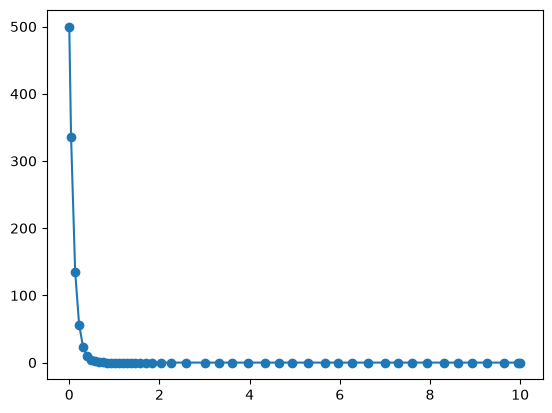

In [14]:
import matplotlib.pyplot as plt
plt.plot(solution.t, solution.y[0])
plt.scatter(solution.t,500*np.exp(-10*solution.t))
plt.show()

That looks good, what about on a log scale?

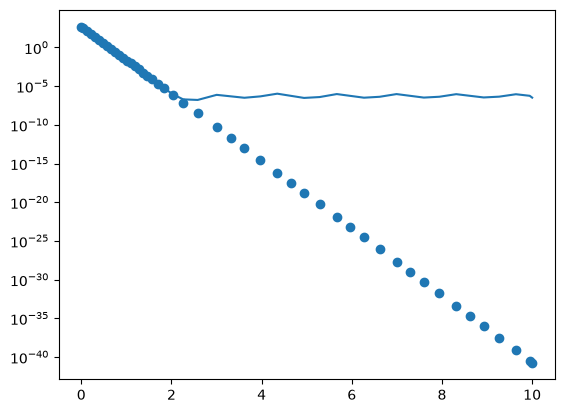

In [15]:
plt.plot(solution.t, solution.y[0])
plt.scatter(solution.t,500*np.exp(-10*solution.t))
plt.yscale('log')
plt.show()

Oh, what happened there? The systems seems to be having trouble with small numbers, it ends up oscillating a solution. There are two fixes:
1. Make the solver be more precise with smaller tolerances
2. Try a different integration method

Lets start with 1:

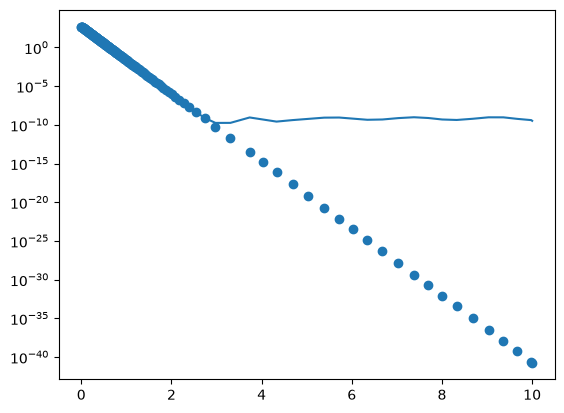

In [16]:
solution = solve_ivp(differential_function,(0,10),np.array([500]),atol=1e-9,rtol=1e-9)
plt.plot(solution.t, solution.y[0])
plt.scatter(solution.t,500*np.exp(-10*solution.t))
plt.yscale('log')
plt.show()

Well that ended up only a little bit better. We could try an implicit integrator like LSODA. These integrators try to solve the state at each time step iteratively. When the derivative depends on its own value, they perform a lot better.

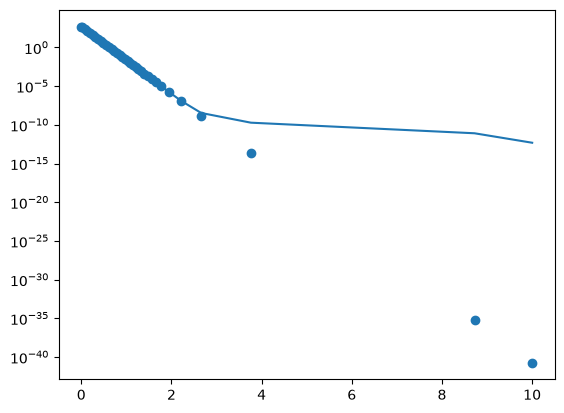

In [17]:
solution = solve_ivp(differential_function,(0,10),np.array([500]),method="Radau")
plt.plot(solution.t, solution.y[0])
plt.scatter(solution.t,500*np.exp(-10*solution.t))
plt.yscale('log')
plt.show()

Not quite there, lets decrease the tolerances as well!

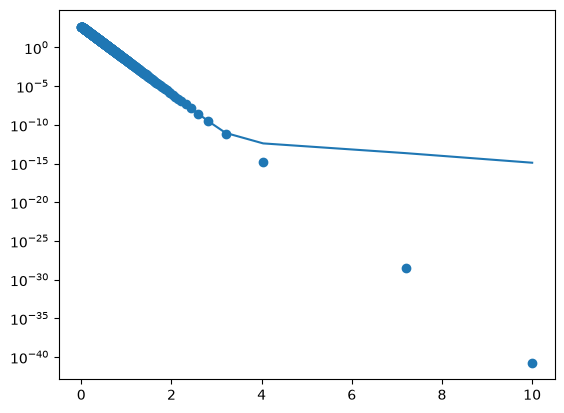

In [18]:
solution = solve_ivp(differential_function,(0,10),np.array([500]),method="Radau",atol=1e-9,rtol=1e-9)
plt.plot(solution.t, solution.y[0])
plt.scatter(solution.t,500*np.exp(-10*solution.t))
plt.yscale('log')
plt.show()

Slightly better again. Maybe we can help the program by reformulating our problem? What if we wanted to integrate this function instead:

$
\frac{d\log N}{dt} = \frac{dN}{dt}/N = -k
$

We can then convert log(N) into N to complete the problem. Lets try:

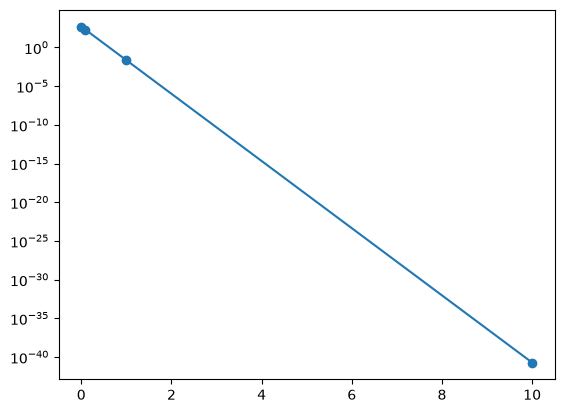

In [20]:
from scipy.integrate import solve_ivp
import numpy as np

def make_log_function(k:float):
    def dlogNdt(time:float, N:float)->float:
        return -k
    return dlogNdt

differential_function = make_log_function(10) #Make a function that takes in time and the number of nuclei remaining

solution = solve_ivp(differential_function,(0,10),np.array([np.log(500)])) #integrate the function from 0 to 10 seconds with an initial value of np.log(500)

plt.plot(solution.t, np.exp(solution.y[0]))
plt.scatter(solution.t,500*np.exp(-10*solution.t))
plt.yscale('log')
plt.show()

Yippee! And the method + tolerances are simple meaning the solution can be found quickly!